# Air Quality Across Monitoring Sites (Beijing)
**Course:** Programming for Data Analysis and Database · **Program:** Big Data Analysis (Master's)
**Cluster 2:** Exploratory Analytics, Time Series & Dashboards
**Team (ADA-2601-2603):** Talant Sakko, Daniyar Yersultanov

**Goal.** Study seasonal PM2.5/PM10 variation across 12 Beijing monitoring sites and the influence of weather, and check whether a simple model forecasts next-day PM2.5 better than naive baselines.

**Dataset.** [Beijing Multi-Site Air Quality](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data) (UCI ML Repository, Zhang et al., 2017): 12 CSV files, 420,768 hourly records, 2013-03-01 – 2017-02-28; 6 pollutants (PM2.5, PM10, SO2, NO2, CO, O3), 6 meteorological variables (TEMP, PRES, DEWP, RAIN, wd, WSPM).

**Notebook structure.** The logic lives in modules under `src/` (requirement 8, modularity); this notebook imports them and walks through every step with results and interpretation.

| Section | Module |
|---|---|
| 1. Loading, memory optimisation, CSV vs Parquet | `src/loader.py` |
| 2. Data quality audit and cleaning | `src/cleaning.py` |
| 3. SQLite database, ER diagram, 10 SQL queries, Pandas vs SQL | `src/database.py` |
| 4. EDA and visualisations | `src/eda.py` |
| 5. Time series: resample, rolling means, decomposition | `src/timeseries.py` |
| 6. Forecasting: baselines vs models | `src/forecasting.py` |
| 7. Dashboard and console menu | `dashboard.py`, `main.py` |

## 0. Setup
Put the dataset (the 12 `PRSA_Data_*.csv` files or the original `.zip`) into `data/raw/`. Archives are unpacked automatically.
In **Google Colab**, uncomment the first lines of the next cell.

In [1]:
# --- Google Colab only ---
# !git clone <REPO_URL> airq && %cd airq
# !pip install -q -r requirements.txt
# from google.colab import files; import shutil
# for name in files.upload(): shutil.move(name, "data/raw/" + name)

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

from src import cleaning, config, database, eda, forecasting, loader, timeseries
from src.utils import load_json

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.ensure_dirs()
print("CSV files found:", len(loader.find_csv_files()))

CSV files found: 12


## 1. Loading data under memory constraints
Each station file is read with `chunksize=50 000` and explicit dtypes (`float32` for measurements, `int8/int16` for date parts, `category` for station and wind direction). We measure time and peak memory for:
1. default `pd.read_csv` (baseline);
2. chunked reading with optimised dtypes;
3. writing / reading the same data as Parquet (full and only 2 columns).

In [2]:
bench = loader.benchmark_loading()
summary = pd.DataFrame([
    {"approach": "CSV, default dtypes",          "time_s": bench["csv_default_dtypes"]["time_s"],     "peak_mem_mb": bench["csv_default_dtypes"]["peak_mem_mb"],     "df_memory_mb": bench["mem_default_mb"],   "file_mb": bench["csv_total_size_mb"]},
    {"approach": "CSV, chunked + optimised dtypes", "time_s": bench["csv_chunked_optimized"]["time_s"], "peak_mem_mb": bench["csv_chunked_optimized"]["peak_mem_mb"], "df_memory_mb": bench["mem_optimized_mb"], "file_mb": bench["csv_total_size_mb"]},
    {"approach": "Parquet, all columns",         "time_s": bench["parquet_read"]["time_s"],           "peak_mem_mb": bench["parquet_read"]["peak_mem_mb"],           "df_memory_mb": bench["mem_optimized_mb"], "file_mb": bench["parquet_size_mb"]},
    {"approach": "Parquet, 2 columns",           "time_s": bench["parquet_read_2cols"]["time_s"],     "peak_mem_mb": bench["parquet_read_2cols"]["peak_mem_mb"],     "df_memory_mb": None,                      "file_mb": bench["parquet_size_mb"]},
])
print(f"Rows: {bench['rows']:,}  ·  memory reduction from dtypes: {bench['mem_reduction_pct']}%")
summary

Loading CSV with default dtypes...


  [csv_default_dtypes] 0.6053 s, peak 103.23 MB
Loading CSV in chunks with optimised dtypes...


  [csv_chunked_optimized] 1.3643 s, peak 50.55 MB
  [parquet_write] 0.1827 s, peak 1.37 MB
Reading Parquet...


  [parquet_read] 0.061 s, peak 6.39 MB
  [parquet_read_2cols] 0.0105 s, peak 0.51 MB
Rows: 420,768  ·  memory reduction from dtypes: 64.5%


,approach,time_s,peak_mem_mb,df_memory_mb,file_mb
0,"CSV, default dtypes",0.6053,103.23,62.10,31.00
1,"CSV, chunked + optimised dtypes",1.3643,50.55,22.07,31.00
2,"Parquet, all columns",0.0610,6.39,22.07,5.87
3,"Parquet, 2 columns",0.0105,0.51,NaN,5.87


**Interpretation.**
- Optimised dtypes cut the DataFrame from ~62 MB to ~22 MB (**−64.5%**) and roughly halve peak memory while loading. Chunked reading is slower than a single `read_csv` call (extra concatenation) — we trade some speed for bounded memory, which matters on larger data.
- Parquet (columnar, snappy-compressed) is **~5× smaller** than CSV (31 MB → 5.9 MB) and an order of magnitude faster to read; reading only the needed columns is faster still. Parquet is therefore the working format for every later step.
- The dataset (420K rows) is the one suggested for this topic, slightly below the 500K-row recommendation; the same pipeline scales because of chunking + Parquet.

## 2. Data quality audit and cleaning
The audit covers feature types, missing values, duplicates, IQR outliers and invalid values.

In [3]:
raw = pd.read_parquet(config.RAW_PARQUET_PATH)
df, report = cleaning.run_audit_and_clean(raw)
before = report["before"]
print("Rows:", before["rows"], "· columns:", before["columns"], "· stations:", len(before["stations"]))
print("Duplicate rows:", before["duplicates_full_rows"], "· duplicate (station, time):", before["duplicates_station_time"])
print("Feature types:", before["feature_types"])

Rows: 420768 · columns: 18 · stations: 12
Duplicate rows: 0 · duplicate (station, time): 0
Feature types: {'numeric_continuous': ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'], 'categorical': ['station', 'wd'], 'temporal': ['year', 'month', 'day', 'hour']}


In [4]:
audit = pd.DataFrame({
    "missing_before": {k: v["count"] for k, v in before["missing"].items()},
    "missing_pct": {k: v["pct"] for k, v in before["missing"].items()},
    "missing_after": report["after_cleaning_missing"],
})
out = pd.DataFrame(before["outliers_iqr"]).T[["lower", "upper", "count", "pct", "max"]]
out.columns = ["iqr_lower", "iqr_upper", "outliers", "outliers_pct", "max"]
audit.join(out, how="outer").loc[config.NUMERIC_COLS + ["wd"]]

,missing_before,missing_pct,missing_after,iqr_lower,iqr_upper,outliers,outliers_pct,max
PM2.5,8739,2.08,3354,-116.50,247.50,19142.0,4.65,999.000000
PM10,6449,1.53,2294,-127.50,308.50,14658.0,3.54,999.000000
SO2,9021,2.14,3896,-22.50,45.50,35566.0,8.64,500.000000
NO2,12116,2.88,5533,-49.00,143.00,7021.0,1.72,290.000000
CO,20701,4.92,11991,-1000.00,3000.00,28054.0,7.01,10000.000000
O3,13277,3.16,5446,-95.50,188.50,16599.0,4.07,1071.000000
TEMP,398,0.09,1,-27.20,53.60,0.0,0.00,41.599998
PRES,393,0.09,1,977.25,1044.05,0.0,0.00,1042.800049
DEWP,403,0.10,1,-44.90,51.10,0.0,0.00,29.100000
RAIN,390,0.09,0,0.00,0.00,16520.0,3.93,72.500000


**Findings and cleaning decisions.**
- No duplicates; every station has a complete hourly grid (35,064 hours).
- Missing values: ≤ 5% per column (CO 4.9%, O3 3.2%, NO2 2.9%, PM2.5 2.1%; weather < 0.1%).
- **Gaps ≤ 6 h are interpolated in time inside each station** (pollution is strongly autocorrelated hour to hour); wind direction is forward-filled. Longer gaps stay missing rather than inventing data — ~74K → ~33K missing cells.
- **IQR outliers are flagged, not removed.** 4.7% of PM2.5 values exceed the upper fence (247.5 µg/m³), but these are real winter haze episodes; removing them would erase the phenomenon we study. They are kept and marked in `pm25_outlier`.
- Isolated O3 values > 500 µg/m³ (25 records, max 1071) are physically implausible spikes and are set to NaN.
- Added features: `datetime`, `season`.

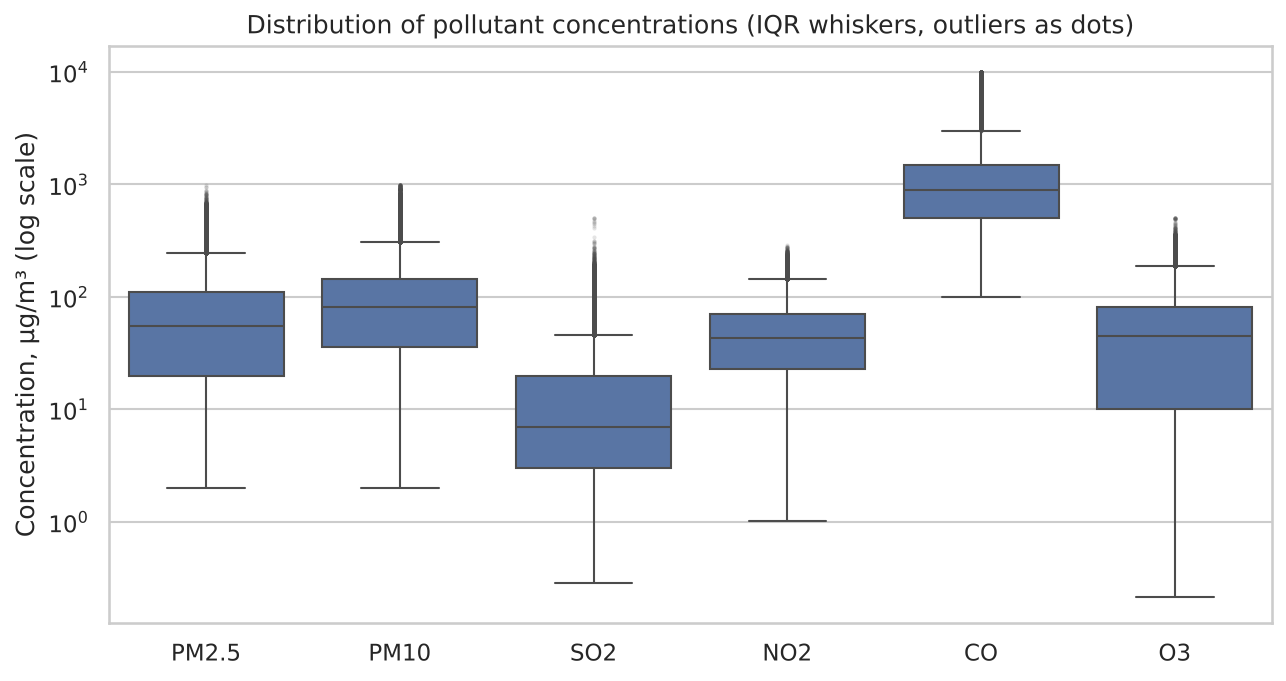

In [5]:
display(Image(eda.plot_boxplots(df)))

Pollutant distributions are strongly right-skewed (log scale needed): most hours are moderate, with long tails of extreme episodes.

## 3. Database: SQLite, ER diagram and SQL
The cleaned data is loaded into a normalised SQLite schema: three lookup tables (`districts`, `stations`, `wind_directions`, `seasons`) and one fact table (`measurements`) with foreign keys, a `UNIQUE(station_id, ts)` constraint and indexes on `(station_id, ts)`, `date`, `(year, month)`.

{'districts': 8, 'stations': 12, 'wind_directions': 16, 'seasons': 12, 'measurements': 420768, 'load_time_s': 2.47}


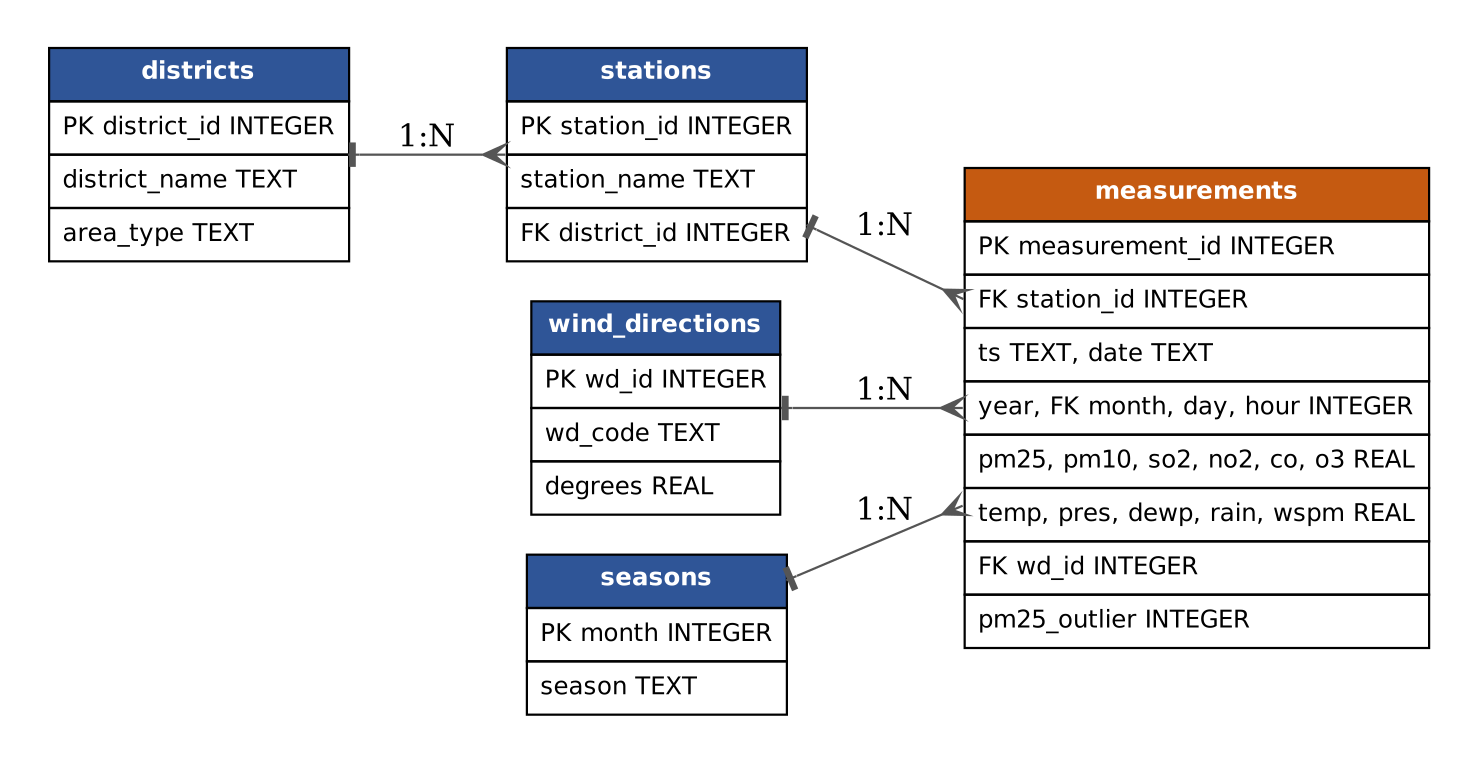

In [6]:
counts = database.build_database(df)
print(counts)
display(Image(database.draw_er_diagram(), width=800))

**Normalisation.** Station names, districts, area types, wind-direction codes and seasons are stored once and referenced by integer keys (3NF): `area_type` depends on the district, not on the measurement, so it lives in `districts`.

### 3.1 SQL queries (10)
| # | Technique |
|---|---|
| q1 | JOIN ×2 + GROUP BY |
| q2 | JOIN + WHERE + GROUP BY + HAVING |
| q3 | Subquery in SELECT and HAVING |
| q4 | CTE + JOIN ×3 |
| q5 | CTE + RANK() OVER (PARTITION BY) |
| q6 | CTE + AVG() OVER (ROWS 6 PRECEDING) — rolling mean |
| q7 | CTE + LAG() — month-over-month and year-over-year change |
| q8 | JOIN + GROUP BY |
| q9 | CTE + CASE — AQI categories |
| q10 | Two CTEs + ROW_NUMBER() — top episodes |

In [7]:
sql_results = {}
for key, q in database.QUERIES.items():
    sql_results[key] = database.run_query(key)
    print(f"{key}: {q['title']}  →  {len(sql_results[key])} rows")

q1_station_avg_join: Average pollutant levels per station with district (JOIN + GROUP BY)  →  12 rows


q2_winter_having: Stations whose winter mean PM2.5 exceeds 100 µg/m³ (GROUP BY + HAVING)  →  6 rows
q3_above_overall_subquery: Stations above the city-wide mean PM2.5 (subquery)  →  8 rows


q4_season_area_cte: Seasonal means by area type (CTE + JOIN)  →  8 rows
q5_yearly_rank_window: Ranking of stations by PM2.5 per monitoring year Mar–Feb (CTE + RANK window)  →  48 rows


q6_rolling_7d_window: Daily PM2.5 with 7-day moving average per station (window AVG ROWS)  →  17532 rows
q7_monthly_change_lag: Month-over-month change of city-wide PM2.5 (CTE + LAG window)  →  48 rows


q8_wind_direction_join: PM2.5 and wind speed by wind direction (JOIN + GROUP BY)  →  16 rows
q9_aqi_category_days: Station-days per AQI category (China HJ 633-2012 PM2.5 breakpoints) per monitoring year (CTE + CASE)  →  24 rows


q10_top_episodes_window: Top-3 most polluted days per station (CTE + ROW_NUMBER window)  →  36 rows


In [8]:
def show(key, n=12):
    print(database.QUERIES[key]["sql"].strip())
    display(sql_results[key].head(n))

show("q1_station_avg_join")

SELECT s.station_name, d.district_name, d.area_type,
       ROUND(AVG(m.pm25),1) AS avg_pm25, ROUND(AVG(m.pm10),1) AS avg_pm10,
       ROUND(AVG(m.no2),1) AS avg_no2, COUNT(*) AS n_hours
FROM measurements m
JOIN stations s  ON s.station_id = m.station_id
JOIN districts d ON d.district_id = s.district_id
GROUP BY s.station_name, d.district_name, d.area_type
ORDER BY avg_pm25 DESC;


,station_name,district_name,area_type,avg_pm25,avg_pm10,avg_no2,n_hours
0,Dongsi,Dongcheng,urban,86.1,110.5,53.6,35064
1,Nongzhanguan,Chaoyang,urban,85.1,109.5,58.2,35064
2,Wanshouxigong,Xicheng,urban,85.0,112.5,55.5,35064
3,Gucheng,Shijingshan,urban,84.0,119.2,55.9,35064
4,Wanliu,Haidian,urban,83.4,110.7,65.3,35064
5,Guanyuan,Xicheng,urban,83.0,109.2,58.0,35064
6,Aotizhongxin,Chaoyang,urban,82.9,110.2,59.3,35064
7,Tiantan,Dongcheng,urban,82.0,106.6,53.2,35064
8,Shunyi,Shunyi,suburban,79.7,99.2,43.8,35064
9,Changping,Changping,suburban,71.2,94.9,44.2,35064


All 8 urban sites have higher mean PM2.5 (82–86 µg/m³) than the 4 suburban sites (66–80); Dingling, the most rural site, is cleanest for PM2.5 but has the highest O3.

In [9]:
show("q2_winter_having")

SELECT s.station_name, ROUND(AVG(m.pm25),1) AS winter_avg_pm25
FROM measurements m
JOIN stations s ON s.station_id = m.station_id
JOIN seasons se ON se.month = m.month
WHERE se.season = 'Winter'
GROUP BY s.station_name
HAVING AVG(m.pm25) > 100
ORDER BY winter_avg_pm25 DESC;


,station_name,winter_avg_pm25
0,Wanshouxigong,108.6
1,Nongzhanguan,104.8
2,Dongsi,103.0
3,Gucheng,101.1
4,Tiantan,100.5
5,Wanliu,100.2


In [10]:
show("q3_above_overall_subquery")

SELECT s.station_name, ROUND(AVG(m.pm25),1) AS avg_pm25,
       ROUND((SELECT AVG(pm25) FROM measurements),1) AS city_avg
FROM measurements m JOIN stations s ON s.station_id = m.station_id
GROUP BY s.station_name
HAVING AVG(m.pm25) > (SELECT AVG(pm25) FROM measurements)
ORDER BY avg_pm25 DESC;


,station_name,avg_pm25,city_avg
0,Dongsi,86.1,79.9
1,Nongzhanguan,85.1,79.9
2,Wanshouxigong,85.0,79.9
3,Gucheng,84.0,79.9
4,Wanliu,83.4,79.9
5,Guanyuan,83.0,79.9
6,Aotizhongxin,82.9,79.9
7,Tiantan,82.0,79.9


In [11]:
show("q4_season_area_cte")

WITH seasonal AS (
    SELECT d.area_type, se.season, AVG(m.pm25) AS pm25, AVG(m.o3) AS o3, AVG(m.so2) AS so2
    FROM measurements m
    JOIN stations s  ON s.station_id = m.station_id
    JOIN districts d ON d.district_id = s.district_id
    JOIN seasons se  ON se.month = m.month
    GROUP BY d.area_type, se.season
)
SELECT area_type, season, ROUND(pm25,1) AS avg_pm25, ROUND(o3,1) AS avg_o3, ROUND(so2,1) AS avg_so2
FROM seasonal ORDER BY area_type, avg_pm25 DESC;


,area_type,season,avg_pm25,avg_o3,avg_so2
0,suburban,Winter,84.3,33.4,24.1
1,suburban,Autumn,72.2,38.8,8.4
2,suburban,Spring,72.2,74.8,15.3
3,suburban,Summer,58.1,93.7,4.7
4,urban,Winter,101.6,27.6,31.0
5,urban,Autumn,87.2,32.7,10.9
6,urban,Spring,79.4,68.8,20.7
7,urban,Summer,67.8,91.4,6.7


Winter is the worst season for PM2.5 and SO2 in both area types (coal heating), while O3 peaks in summer (photochemistry needs sunlight and heat) — PM2.5 and O3 move in opposite directions over the year.

In [12]:
show("q5_yearly_rank_window", 24)

WITH yearly AS (
    SELECT CASE WHEN m.month >= 3 THEN m.year ELSE m.year - 1 END AS mon_year,
           s.station_name, AVG(m.pm25) AS avg_pm25
    FROM measurements m JOIN stations s ON s.station_id = m.station_id
    GROUP BY mon_year, s.station_name
)
SELECT mon_year || '-' || (mon_year + 1) AS monitoring_year, station_name,
       ROUND(avg_pm25,1) AS avg_pm25,
       RANK() OVER (PARTITION BY mon_year ORDER BY avg_pm25 DESC) AS rank_in_year
FROM yearly ORDER BY mon_year, rank_in_year;


,monitoring_year,station_name,avg_pm25,rank_in_year
0,2013-2014,Wanliu,98.4,1
1,2013-2014,Dongsi,93.6,2
2,2013-2014,Wanshouxigong,92.2,3
3,2013-2014,Nongzhanguan,91.7,4
4,2013-2014,Gucheng,89.4,5
5,2013-2014,Tiantan,89.2,6
6,2013-2014,Guanyuan,88.9,7
7,2013-2014,Aotizhongxin,88.6,8
8,2013-2014,Shunyi,85.2,9
9,2013-2014,Changping,79.1,10


In [13]:
show("q6_rolling_7d_window", 10)

WITH daily AS (
    SELECT s.station_name, m.date, AVG(m.pm25) AS pm25
    FROM measurements m JOIN stations s ON s.station_id = m.station_id
    GROUP BY s.station_name, m.date
)
SELECT station_name, date, ROUND(pm25,1) AS daily_pm25,
       ROUND(AVG(pm25) OVER (PARTITION BY station_name ORDER BY date
                             ROWS BETWEEN 6 PRECEDING AND CURRENT ROW),1) AS ma7_pm25
FROM daily ORDER BY station_name, date;


,station_name,date,daily_pm25,ma7_pm25
0,Aotizhongxin,2013-03-01,7.1,7.1
1,Aotizhongxin,2013-03-02,30.8,18.9
2,Aotizhongxin,2013-03-03,76.9,38.3
3,Aotizhongxin,2013-03-04,22.7,34.4
4,Aotizhongxin,2013-03-05,148.9,57.3
5,Aotizhongxin,2013-03-06,223.3,84.9
6,Aotizhongxin,2013-03-07,263.4,110.4
7,Aotizhongxin,2013-03-08,221.5,141.0
8,Aotizhongxin,2013-03-09,62.0,145.5
9,Aotizhongxin,2013-03-10,34.3,139.4


In [14]:
show("q7_monthly_change_lag", 15)

WITH monthly AS (
    SELECT year, month, AVG(pm25) AS pm25 FROM measurements GROUP BY year, month
)
SELECT year, month, ROUND(pm25,1) AS avg_pm25,
       ROUND(pm25 - LAG(pm25) OVER (ORDER BY year, month),1) AS change_vs_prev,
       ROUND(pm25 - LAG(pm25,12) OVER (ORDER BY year, month),1) AS change_vs_last_year
FROM monthly ORDER BY year, month;


,year,month,avg_pm25,change_vs_prev,change_vs_last_year
0,2013,3,104.8,NaN,NaN
1,2013,4,62.2,-42.6,NaN
2,2013,5,81.9,19.7,NaN
3,2013,6,101.9,20.0,NaN
4,2013,7,67.9,-34.0,NaN
5,2013,8,60.6,-7.3,NaN
6,2013,9,76.1,15.5,NaN
7,2013,10,91.9,15.7,NaN
8,2013,11,73.8,-18.1,NaN
9,2013,12,78.3,4.5,NaN


In [15]:
show("q8_wind_direction_join", 16)

SELECT w.wd_code, w.degrees, ROUND(AVG(m.pm25),1) AS avg_pm25,
       ROUND(AVG(m.wspm),2) AS avg_wind_speed, COUNT(*) AS n_hours
FROM measurements m JOIN wind_directions w ON w.wd_id = m.wd_id
GROUP BY w.wd_code, w.degrees ORDER BY w.degrees;


,wd_code,degrees,avg_pm25,avg_wind_speed,n_hours
0,N,0.0,67.2,1.61,30979
1,NNE,22.5,71.2,1.53,28330
2,NE,45.0,86.3,1.40,43653
3,ENE,67.5,97.9,1.34,34215
4,E,90.0,101.7,1.31,29822
5,ESE,112.5,102.1,1.54,24264
6,SE,135.0,96.9,1.52,20211
7,SSE,157.5,93.6,1.67,17741
8,S,180.0,89.5,1.73,19443
9,SSW,202.5,84.2,1.83,22606


Northern / north-western winds bring the cleanest air (≈ 52–57 µg/m³) and the highest wind speeds; easterly and south-easterly winds bring ≈ 100 µg/m³ — they are weak and carry air from the industrial plain south-east of Beijing.

In [16]:
show("q9_aqi_category_days", 24)
sql_results["q9_aqi_category_days"].pivot(index="monitoring_year", columns="category", values="station_days")

WITH daily AS (
    SELECT station_id, date,
           CASE WHEN month >= 3 THEN year ELSE year - 1 END AS mon_year, AVG(pm25) AS pm25
    FROM measurements GROUP BY station_id, date
)
SELECT mon_year || '-' || (mon_year + 1) AS monitoring_year,
       CASE WHEN pm25 <= 35  THEN '1 Excellent'
            WHEN pm25 <= 75  THEN '2 Good'
            WHEN pm25 <= 115 THEN '3 Light'
            WHEN pm25 <= 150 THEN '4 Moderate'
            WHEN pm25 <= 250 THEN '5 Heavy'
            ELSE '6 Severe' END AS category,
       COUNT(*) AS station_days
FROM daily WHERE pm25 IS NOT NULL
GROUP BY mon_year, category ORDER BY mon_year, category;


,monitoring_year,category,station_days
0,2013-2014,1 Excellent,998
1,2013-2014,2 Good,1377
2,2013-2014,3 Light,844
3,2013-2014,4 Moderate,503
4,2013-2014,5 Heavy,472
5,2013-2014,6 Severe,169
6,2014-2015,1 Excellent,1196
7,2014-2015,2 Good,1283
8,2014-2015,3 Light,842
9,2014-2015,4 Moderate,481


category,1 Excellent,2 Good,3 Light,4 Moderate,5 Heavy,6 Severe
monitoring_year,,,,,,
2013-2014,998,1377,844,503,472,169
2014-2015,1196,1283,842,481,429,122
2015-2016,1582,1297,673,364,318,151
2016-2017,1387,1292,832,311,392,159


Monitoring years run March–February so every year has one full winter. "Excellent" days grew from 998 to ~1,200–1,580 station-days after 2013-14, but heavy + severe days stayed high (≈ 470–640 per year).

In [17]:
show("q10_top_episodes_window", 12)

WITH daily AS (
    SELECT s.station_name, m.date, AVG(m.pm25) AS pm25, AVG(m.wspm) AS wspm, AVG(m.dewp) AS dewp
    FROM measurements m JOIN stations s ON s.station_id = m.station_id
    GROUP BY s.station_name, m.date
), ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY station_name ORDER BY pm25 DESC) AS rn
    FROM daily
)
SELECT station_name, date, ROUND(pm25,1) AS daily_pm25, ROUND(wspm,2) AS avg_wind, ROUND(dewp,1) AS avg_dewp, rn
FROM ranked WHERE rn <= 3 ORDER BY station_name, rn;


,station_name,date,daily_pm25,avg_wind,avg_dewp,rn
0,Aotizhongxin,2015-12-25,512.3,1.35,-3.8,1
1,Aotizhongxin,2015-12-01,495.4,1.19,-0.5,2
2,Aotizhongxin,2017-01-01,464.1,1.10,-5.0,3
3,Changping,2017-01-01,433.5,1.05,-8.5,1
4,Changping,2016-12-21,414.3,0.96,-3.0,2
5,Changping,2016-12-20,383.8,0.97,-4.8,3
6,Dingling,2015-12-01,418.6,1.01,-2.3,1
7,Dingling,2016-12-21,400.4,0.96,-3.0,2
8,Dingling,2015-12-26,391.5,1.29,-5.3,3
9,Dongsi,2015-12-25,567.4,1.35,-3.8,1


### 3.2 Pandas vs SQL (approach comparison)

In [18]:
pvs = database.benchmark_pandas_vs_sql(df)
pd.DataFrame({
    "operation": ["monthly mean PM2.5 per station", "monthly mean PM2.5 per station", "load full table", "load full table"],
    "engine": ["Pandas groupby (in memory)", "SQLite GROUP BY + JOIN", "SQLite SELECT * → Pandas", "Parquet → Pandas"],
    "time_s": [pvs["pandas_groupby_s"], pvs["sqlite_groupby_s"], pvs["sqlite_full_read_s"], pvs["parquet_full_read_s"]],
}).assign(max_abs_difference=pvs["max_abs_diff"])

,operation,engine,time_s,max_abs_difference
0,monthly mean PM2.5 per station,Pandas groupby (in memory),0.0201,0.000011
1,monthly mean PM2.5 per station,SQLite GROUP BY + JOIN,0.1788,0.000011
2,load full table,SQLite SELECT * → Pandas,2.6833,0.000011
3,load full table,Parquet → Pandas,0.0393,0.000011


Both engines return identical results (difference ~1e-5, float32 rounding). When data already sits in memory, Pandas aggregates ~10× faster; SQLite wins for persistent storage, constraints, joins over normalised tables and reproducible queries without loading everything. Pulling the whole table from SQLite is ~70× slower than Parquet, so we **store in SQLite, analyse in Pandas, and cache in Parquet**.

## 4. Exploratory data analysis

In [19]:
desc = eda.descriptive_stats(df)
desc

,count,mean,std,min,25%,50%,75%,95%,max,skew,missing_pct
PM2.5,417414.0,79.88,81.04,2.00,20.00,55.0,111.0,242.0,999.0,2.020000,0.80
PM10,418474.0,104.86,92.47,2.00,36.00,82.0,145.0,280.0,999.0,1.930000,0.55
SO2,416872.0,15.87,21.79,0.29,3.00,7.0,20.0,60.0,500.0,3.100000,0.93
NO2,415235.0,50.54,35.18,1.03,23.00,43.0,71.0,117.0,290.0,1.050000,1.31
CO,408777.0,1234.02,1170.92,100.00,500.00,900.0,1500.0,3500.0,10000.0,2.610000,2.85
O3,415322.0,57.08,56.29,0.21,10.07,45.0,82.0,177.0,500.0,1.480000,1.29
TEMP,420767.0,13.53,11.44,-19.90,3.10,14.5,23.3,30.6,41.6,-0.100000,0.00
PRES,420767.0,1010.75,10.47,982.40,1002.30,1010.4,1019.0,1027.9,1042.8,0.110000,0.00
DEWP,420767.0,2.48,13.80,-43.40,-8.90,3.0,15.1,22.1,29.1,-0.190000,0.00
RAIN,420768.0,0.06,0.82,0.00,0.00,0.0,0.0,0.0,72.5,30.059999,0.00


Mean PM2.5 is 79.9 µg/m³ against a median of ~55 (skew ≈ 2): the average is driven by severe episodes. For reference, China's Grade II 24-h standard is 75 µg/m³; **40% of station-days exceed it**.

,PM2.5,PM10,SO2,NO2,CO,O3,area_type
station,,,,,,,
Dongsi,86.099998,110.500000,18.600000,53.599998,1333.400024,56.900002,urban
Nongzhanguan,85.099998,109.500000,18.799999,58.200001,1332.500000,58.500000,urban
Wanshouxigong,85.000000,112.500000,17.200001,55.500000,1372.699951,56.000000,urban
Gucheng,84.000000,119.199997,15.500000,55.900002,1327.400024,57.700001,urban
Wanliu,83.400002,110.699997,18.400000,65.300003,1326.300049,47.900002,urban
Guanyuan,83.000000,109.199997,17.600000,58.000000,1267.599976,55.299999,urban
Aotizhongxin,82.900002,110.199997,17.400000,59.299999,1268.300049,55.799999,urban
Tiantan,82.000000,106.599998,14.400000,53.200001,1301.900024,55.900002,urban
Shunyi,79.699997,99.199997,13.600000,43.799999,1191.099976,54.700001,suburban


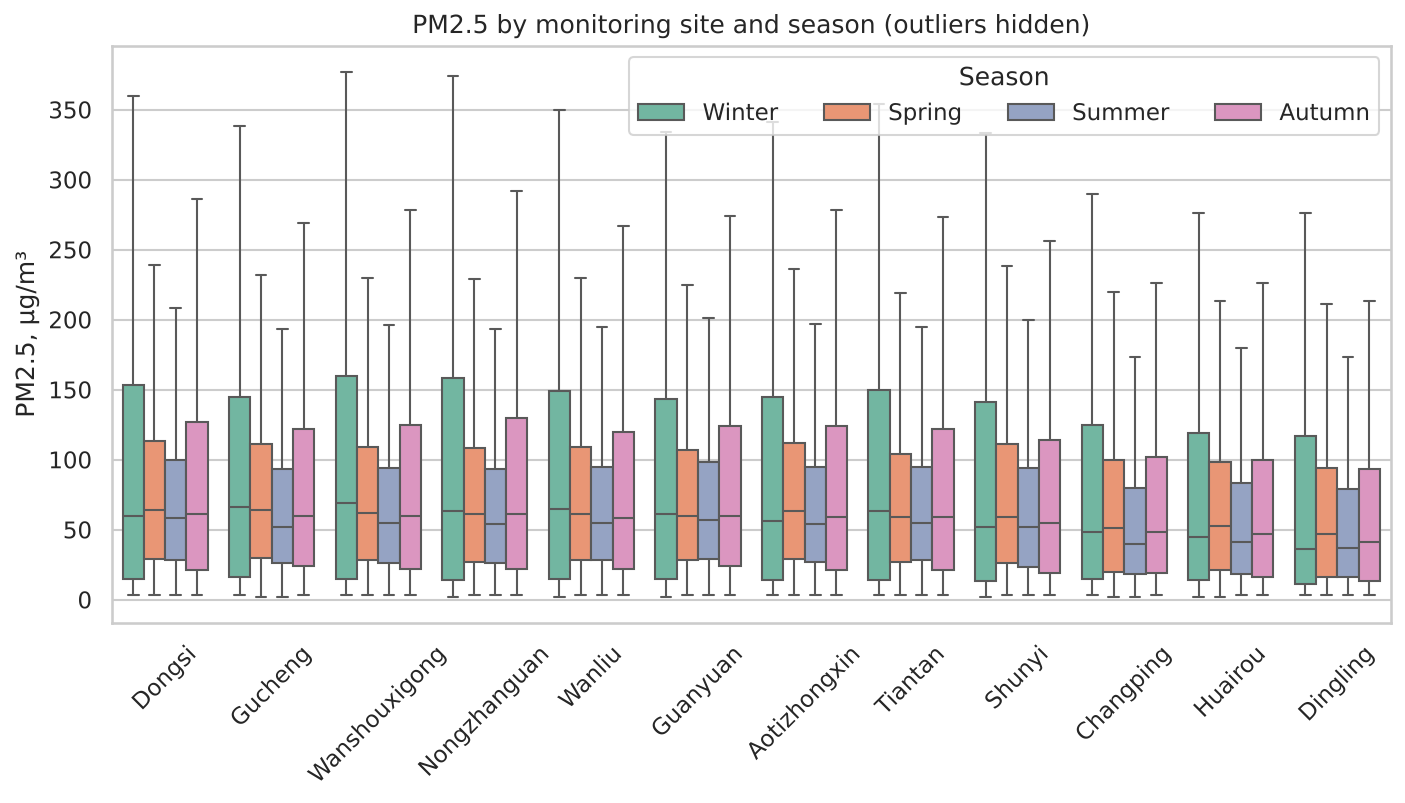

In [20]:
display(eda.station_summary(df))
display(Image(eda.plot_station_boxplot(df)))

Urban sites are consistently above suburban ones in every season; the gap is largest in winter. Winter has both the highest median and the widest spread (stagnant, cold-air episodes).

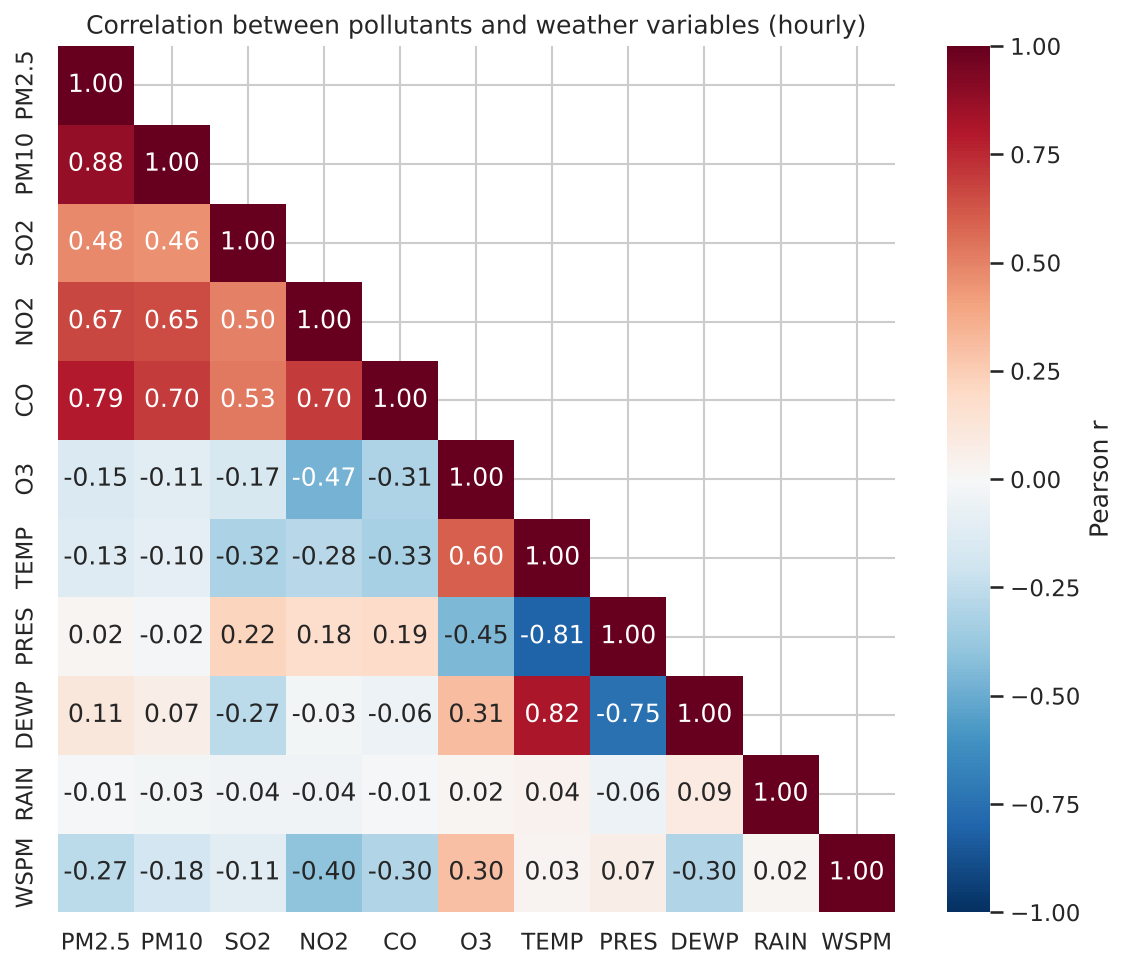

In [21]:
corr, corr_path = eda.correlation(df)
display(Image(corr_path))

- PM2.5 is strongly correlated with PM10 (0.88) and CO (0.79), and moderately with NO2 (0.67) and SO2 (0.48) — common combustion sources.
- O3 is negatively correlated with NO2 (−0.47) and positively with temperature (0.60): it is formed photochemically and titrated by NO.
- Among weather variables, wind speed has the clearest effect on PM2.5 (r = −0.27; Spearman −0.33). Linear correlations with temperature, pressure and dew point are weak because the relationships are non-linear (next plot).

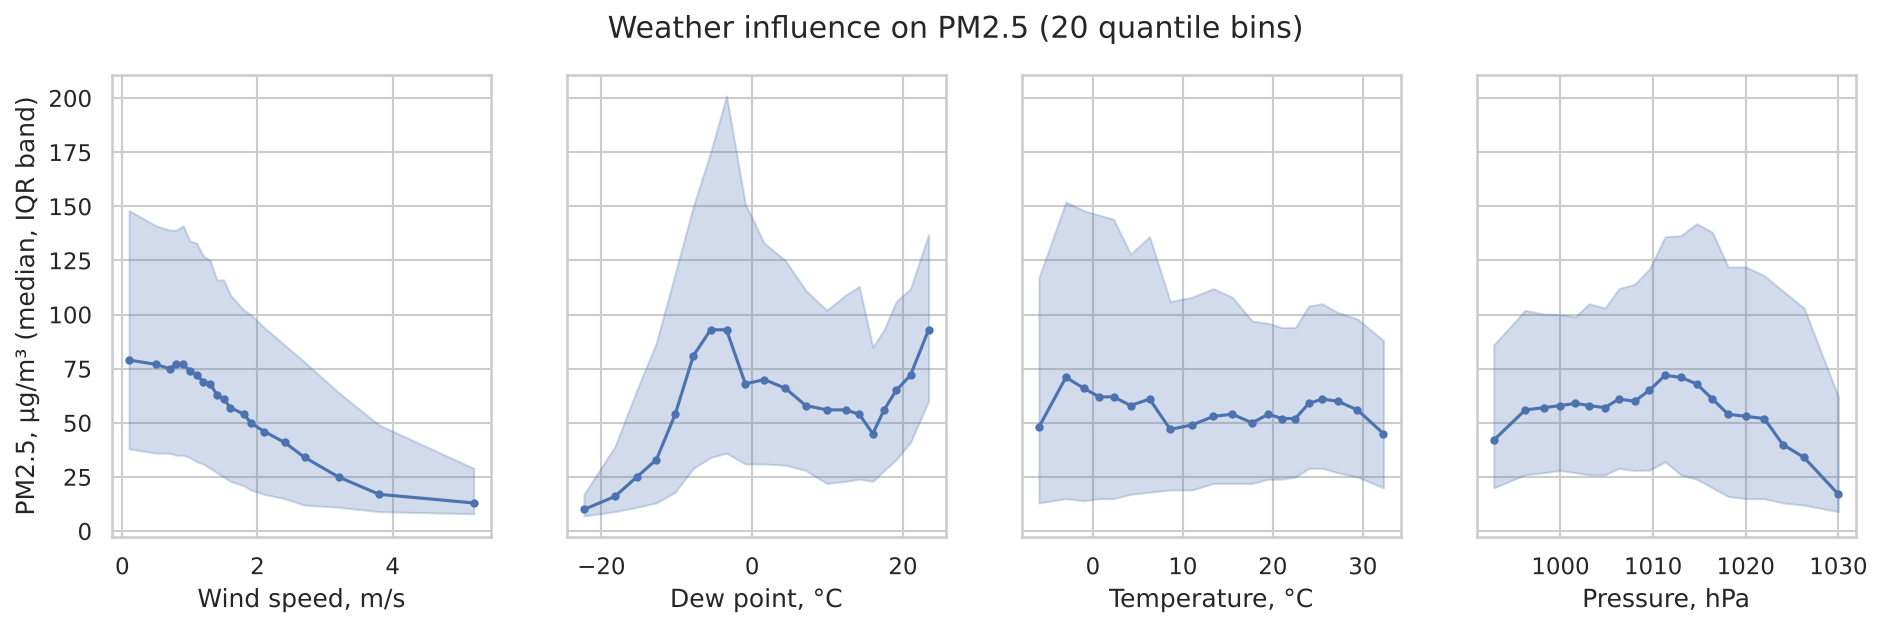

In [22]:
display(Image(eda.plot_weather_influence(df)))

**Weather influence.**
- **Wind speed:** median PM2.5 falls from ~78 µg/m³ in calm air to ~13 µg/m³ above 5 m/s — ventilation is the strongest single driver.
- **Dew point (humidity):** very dry air (dew point < −15 °C, cold northern air masses) is clean; humid air in winter (dew point ≈ −5 °C) coincides with the worst haze, since moisture promotes secondary particle formation.
- **Pressure:** very high pressure (> 1025 hPa, strong cold fronts) is clean.

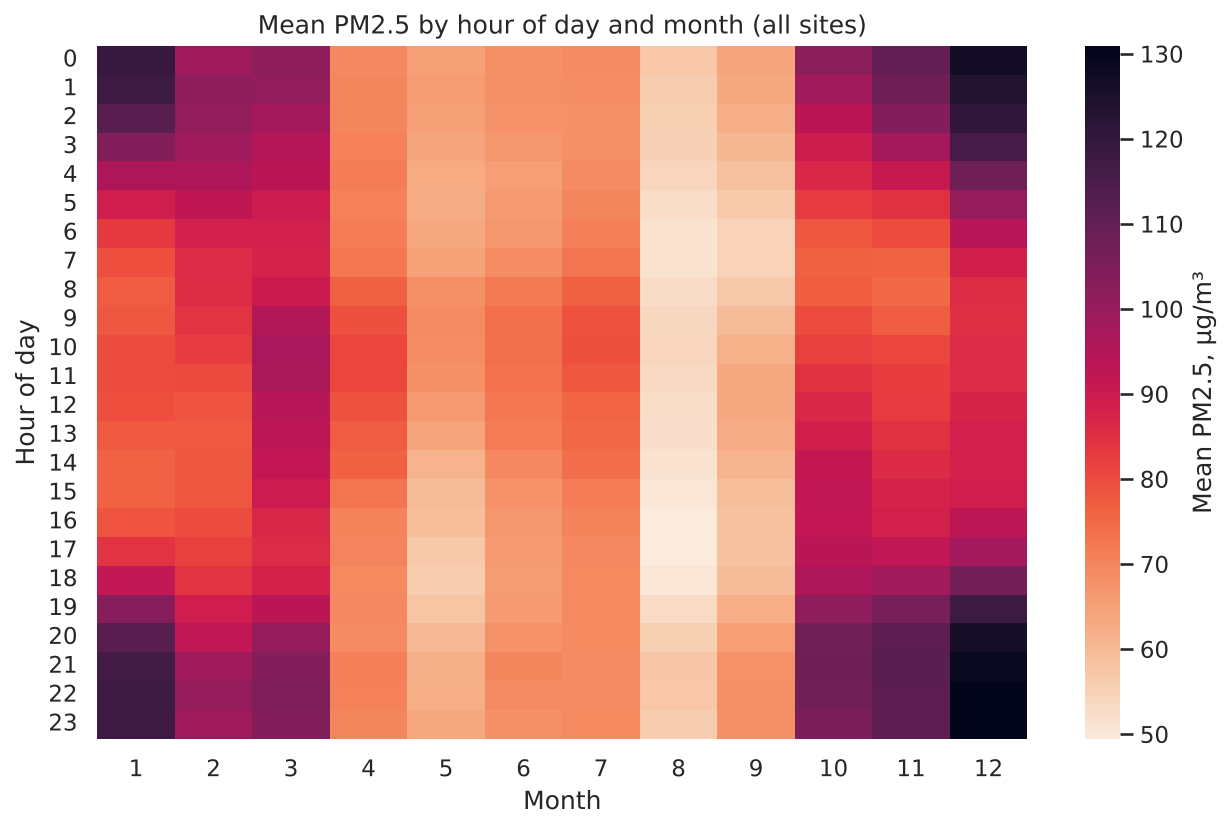

In [23]:
display(Image(eda.plot_hour_month_heatmap(df)))

PM2.5 is highest at night (peak ≈ 22:00, 89 µg/m³) and lowest in the morning (≈ 07:00, 73 µg/m³): the nocturnal boundary layer is shallow and traps emissions; the effect is strongest from November to February.

**Interactive visualisations (Plotly)** — click legend entries to filter sites, hover for values.

In [24]:
eda.interactive_trend_fig(df).show()

In [25]:
eda.interactive_wind_fig(df).show()

In [26]:
eda.plot_interactive_trend(df); eda.plot_interactive_wind(df)   # saved as HTML in reports/figures

'/home/claude/airq/reports/figures/07_interactive_wind_polar.html'

## 5. Time-series analysis
The city-wide series is the mean over 12 sites. We resample to daily / weekly / monthly frequency, compute 7-, 30- and 365-day moving averages, and run additive seasonal decomposition with three periods: 12 (annual cycle on monthly data), 7 (weekly cycle on daily data) and 24 (daily cycle on hourly data).
Seasonal strength = 1 − Var(residual) / Var(seasonal + residual) (Hyndman & Athanasopoulos).

{'daily': 1461, 'weekly': 210, 'monthly': 48}


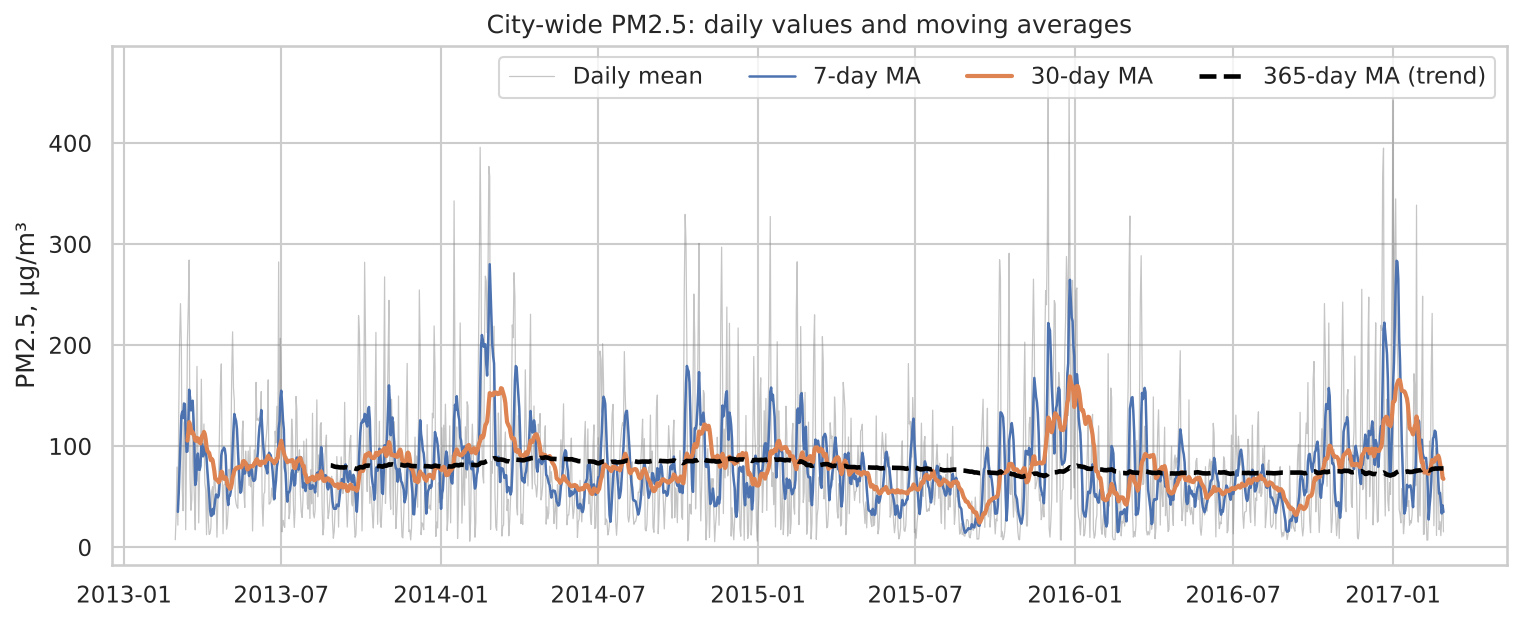

In [27]:
hourly = timeseries.city_series(df)
levels = timeseries.resample_levels(hourly)
print({k: len(v) for k, v in levels.items()})
display(Image(timeseries.plot_rolling(levels["daily"])))

The 365-day moving average shows a downward trend through 2015 and a slight rebound in 2016-17; daily values swing between < 20 and > 400 µg/m³ within days.

In [28]:
ts_out = timeseries.run_timeseries(df)
pd.DataFrame(ts_out["summary"]).T

,period,seasonal_strength,seasonal_amplitude,trend_start,trend_end
monthly_period12,12.0,0.400,45.65,87.14,76.67
daily_period7,7.0,0.007,14.58,102.22,34.75
hourly_period24,24.0,0.041,15.67,7.43,15.89


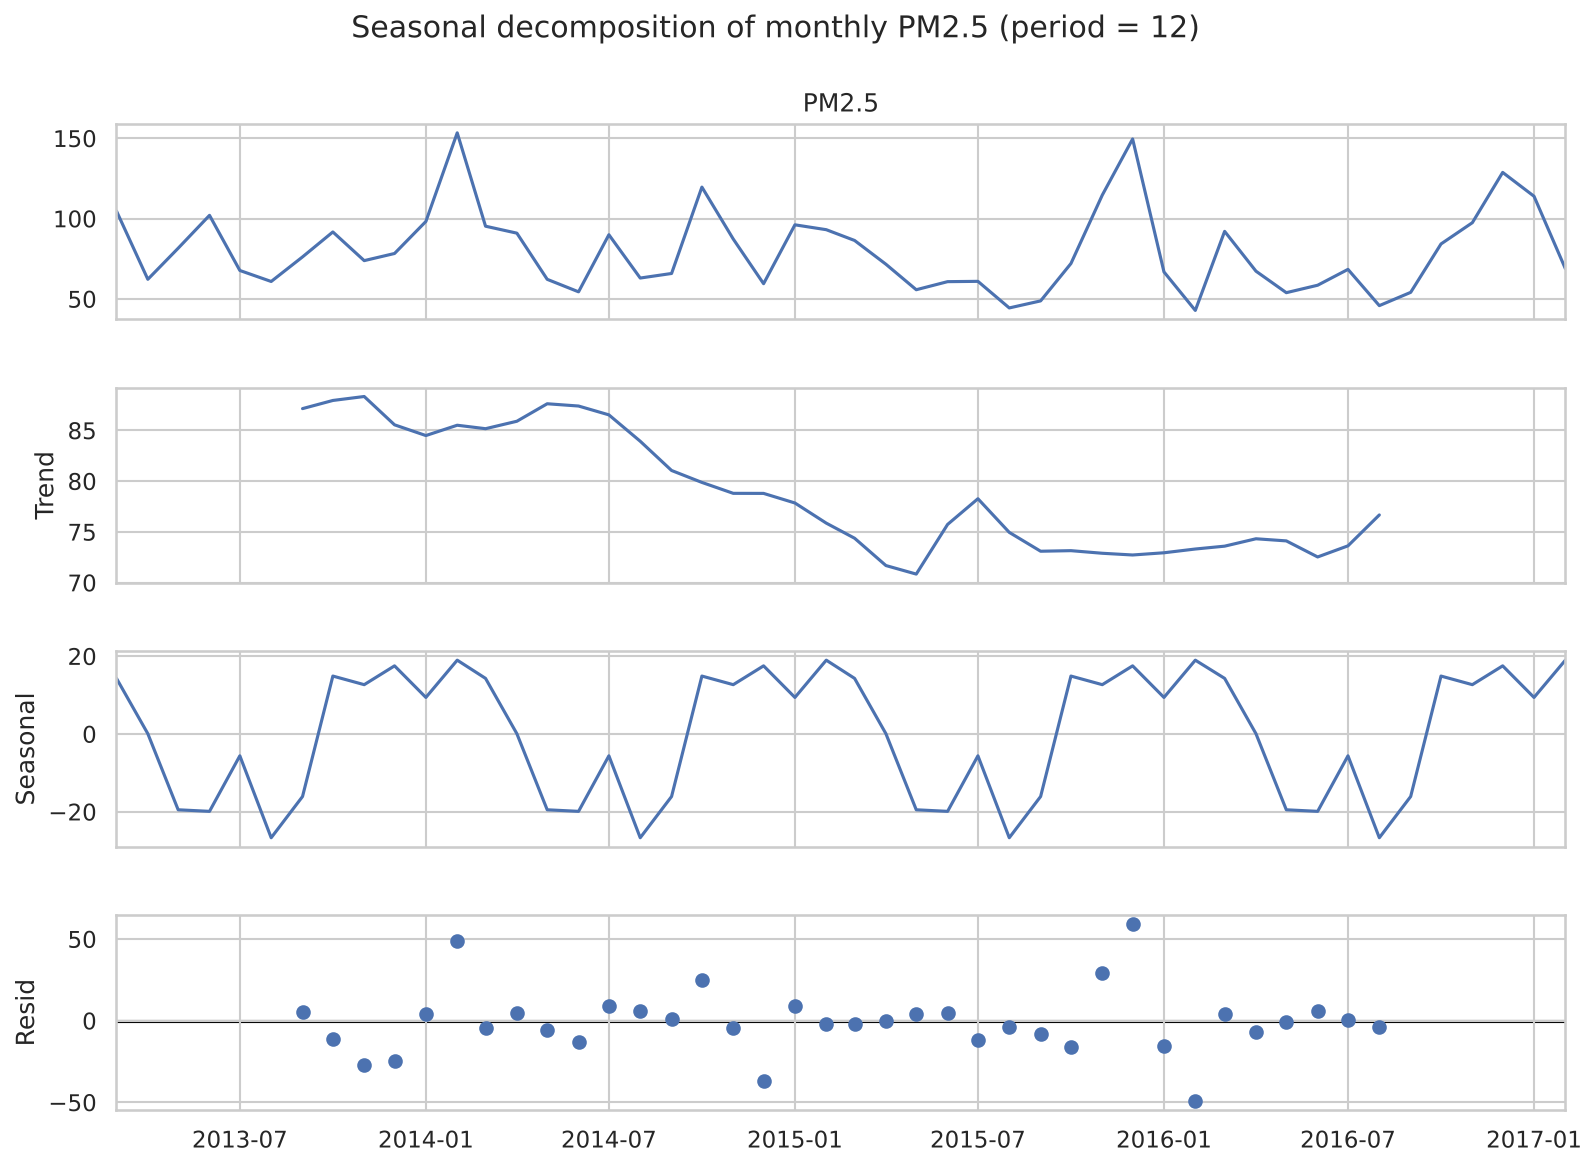

In [29]:
display(Image(config.FIG_DIR / '09_decomposition_monthly.png'))

- **Annual cycle (period 12):** seasonal strength 0.40, amplitude ≈ 46 µg/m³ between the cleanest months (Aug, Apr–May) and the worst (Dec–Feb). Trend falls from ≈ 87 to ≈ 73–77 µg/m³.
- **Weekly cycle (period 7):** seasonal strength ≈ 0.01 — practically no weekday/weekend effect; PM2.5 is driven by weather, not by the working week.
- **Daily cycle (period 24):** weak relative to day-to-day variation (0.04) but systematic (night peak).

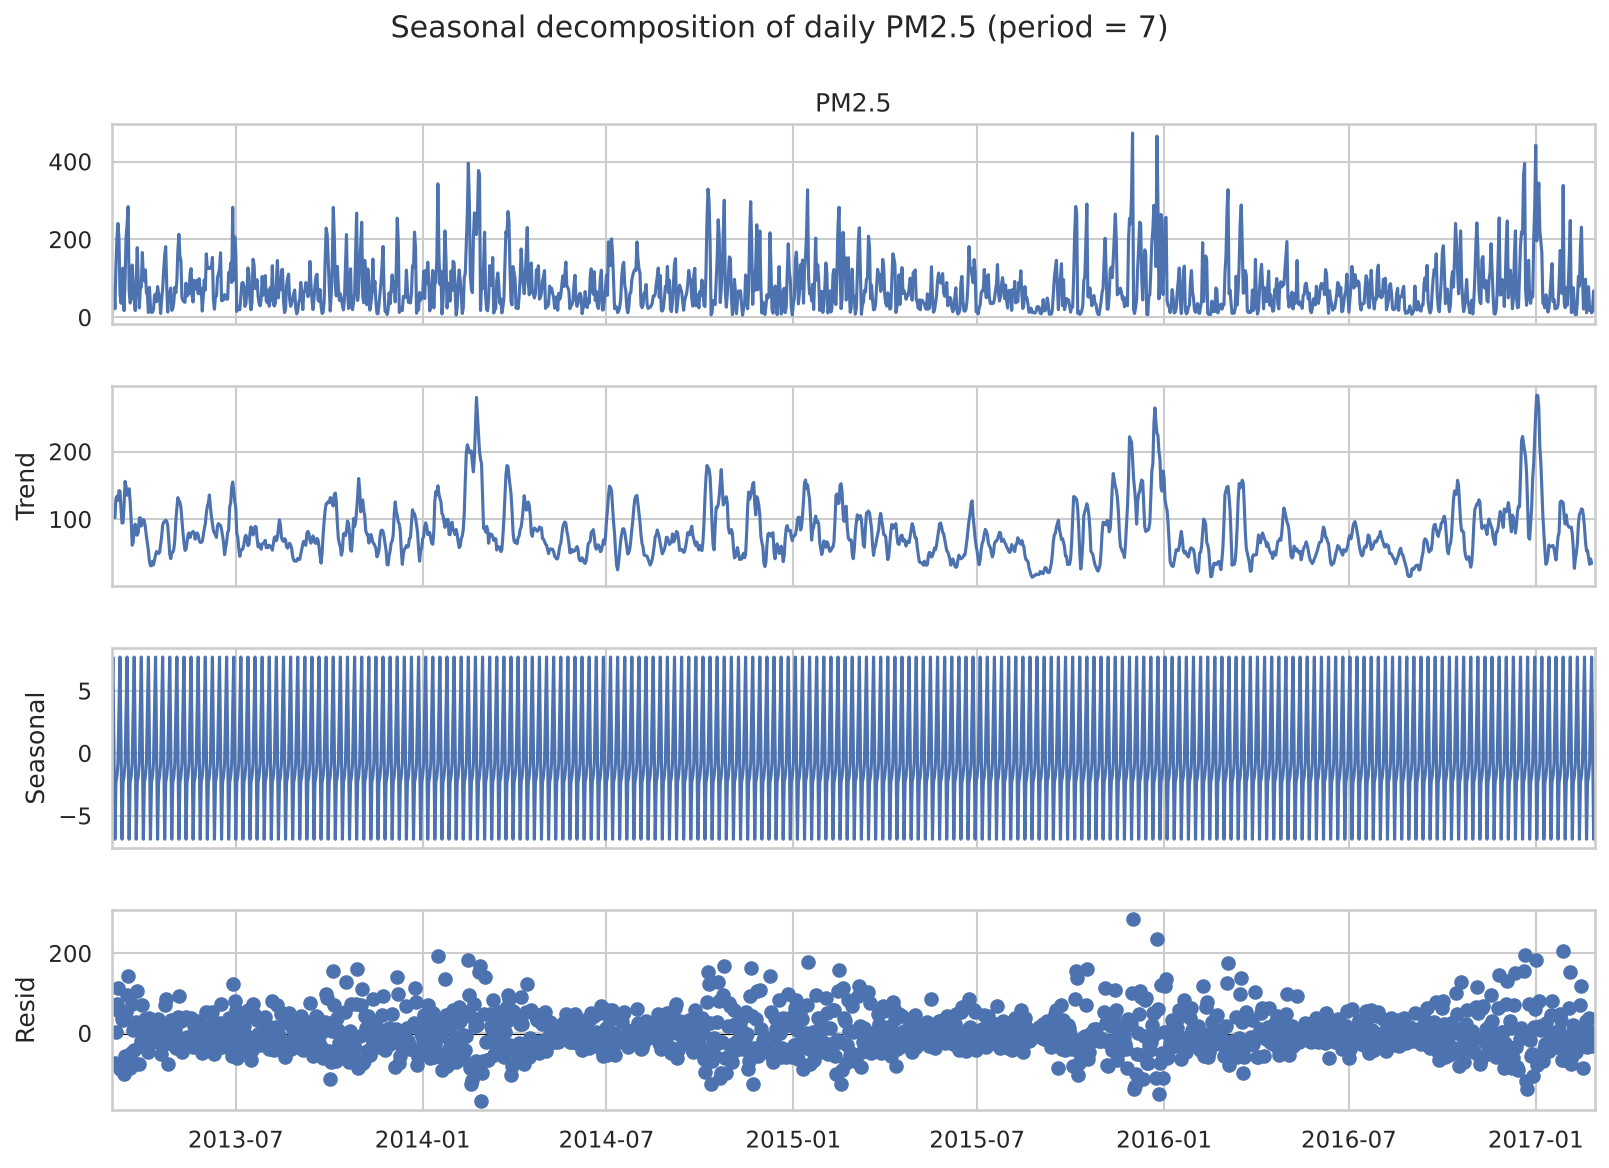

In [30]:
display(Image(config.FIG_DIR / '10_decomposition_weekly.png'))

### Site comparison of the seasonal component

In [31]:
ts_out['stations']

,station,area_type,mean_pm25,seasonal_strength,amplitude,peak_month,trend_change
3,Dongsi,urban,86.1,0.376,46.3,2,-7.7
7,Nongzhanguan,urban,85.2,0.488,57.6,12,-10.1
11,Wanshouxigong,urban,85.1,0.495,57.2,12,-8.5
5,Gucheng,urban,84.0,0.385,49.1,12,-6.9
10,Wanliu,urban,83.5,0.434,49.4,12,-22.0
4,Guanyuan,urban,83.0,0.370,42.2,12,-6.9
0,Aotizhongxin,urban,82.6,0.377,45.4,10,-9.6
9,Tiantan,urban,82.1,0.432,49.0,12,-10.3
8,Shunyi,suburban,79.7,0.359,50.3,2,-8.6
1,Changping,suburban,71.2,0.349,45.3,2,-13.0


All 12 sites share the same annual cycle (strength 0.35–0.50). Most central urban sites peak in **December**, suburban northern sites (Changping, Dingling, Huairou, Shunyi) in **February**. Every site shows a downward trend (−7 to −22 µg/m³), the largest at Wanliu.

## 6. Forecasting next-day PM2.5: baselines vs models
**Task:** predict the daily mean PM2.5 of day *t* for each site.
**Split (time-based, no shuffling):** train 2013-03 – 2016-02, test 2016-03 – 2017-02 (one full year, all seasons).
**Leakage control:** every feature uses information up to day *t−1* only (lags, moving averages computed on shifted values, previous-day weather); the scaler is fitted on train only; all approaches are scored on exactly the same test rows.

| Approach | Type | Prediction |
|---|---|---|
| Naive | baseline | y(t−1) |
| Seasonal naive | baseline | y(t−7) |
| Moving average | simple | mean of y(t−7 … t−1) |
| Linear Regression | model | lags 1,2,3,7, MA7, MA30, day-of-year sin/cos, weekend, weather (t−1), station dummies |
| Gradient Boosting | extension | same features, HistGradientBoostingRegressor |

In [32]:
fc = forecasting.evaluate(df)
print(fc["meta"])
fc["results"]

{'train_rows': 12770, 'test_rows': 4350, 'train_period': ['2013-03-21', '2016-02-29'], 'test_period': ['2016-03-01', '2017-02-28'], 'n_features': 26}


,approach,type,MAE,RMSE,time_s,peak_mem_mb,skill_vs_naive_%
0,Naive (y[t-1]),baseline,44.23,65.82,0.000,0.00,0.0
1,Seasonal naive (y[t-7]),baseline,69.08,100.92,0.000,0.00,-56.2
2,Moving average (7 days),simple,53.43,73.92,0.000,0.00,-20.8
3,Linear Regression (lags + weather t-1),model,39.01,56.39,0.029,5.54,11.8
4,Gradient Boosting (extension),model,37.26,55.41,3.088,10.57,15.8


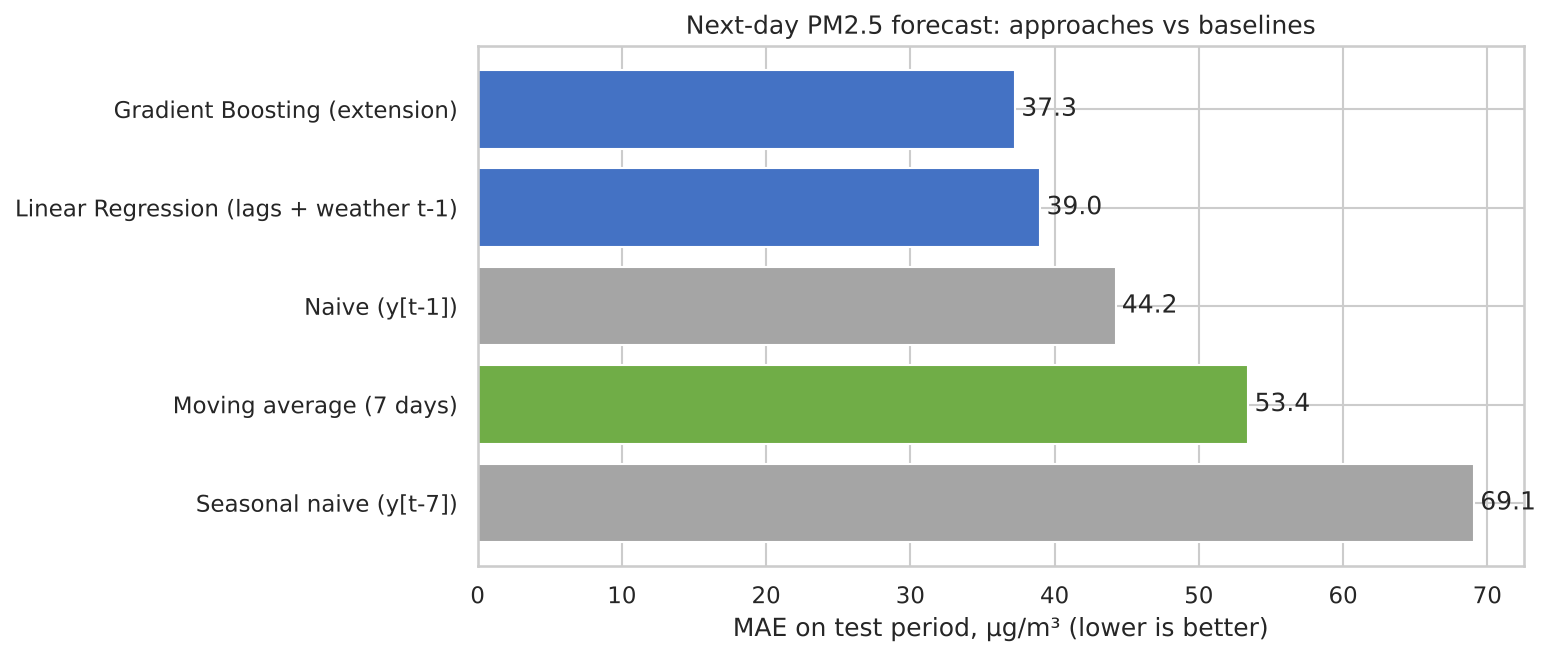

In [33]:
display(Image(fc['figures'][0]))

In [34]:
fc['per_station']

,station,Naive (y[t-1]),Seasonal naive (y[t-7]),Moving average (7 days),Linear Regression (lags + weather t-1),Gradient Boosting (extension)
0,Aotizhongxin,46.13,70.32,54.74,39.99,38.01
1,Changping,38.25,60.33,46.46,33.52,30.87
2,Dingling,39.15,59.61,45.92,34.01,32.33
3,Dongsi,48.18,76.98,59.49,43.41,41.40
4,Guanyuan,45.74,73.01,56.00,40.49,38.76
5,Gucheng,47.01,72.78,56.97,41.63,38.73
6,Huairou,39.32,59.98,46.33,32.93,32.17
7,Nongzhanguan,46.85,73.16,56.77,41.88,39.01
8,Shunyi,45.51,70.43,54.22,39.07,38.44
9,Tiantan,44.27,69.51,53.84,39.72,38.48


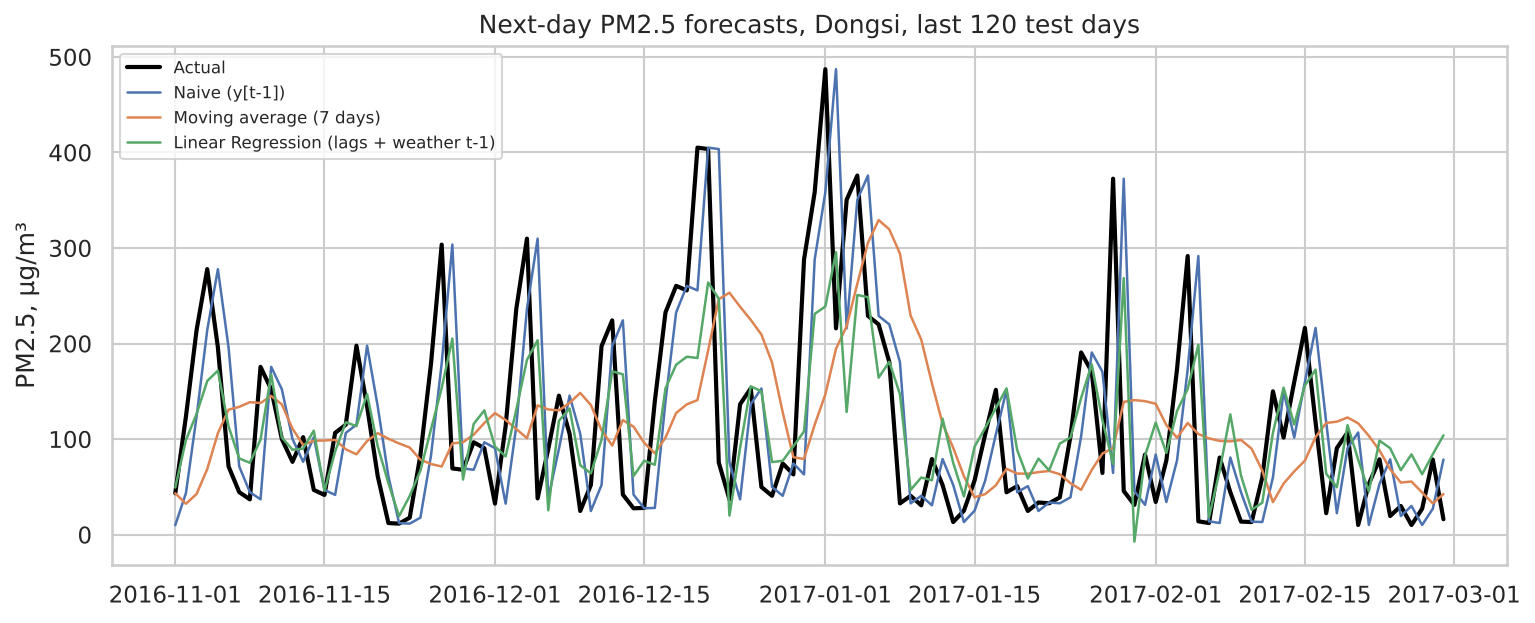

In [35]:
display(Image(fc['figures'][1]))

**Results and justification.**
- **Naive y(t−1)** is a strong baseline (MAE 44.2): pollution persists from day to day. **Seasonal naive** (MAE 69.1) and the **7-day moving average** (MAE 53.4) are worse — there is no weekly cycle, and averaging over a week lags behind episodes that build up and clear within 2–4 days.
- **Linear Regression** lowers MAE to 39.0 (**−11.8% vs naive**) at negligible cost (≈ 0.03 s, ≈ 6 MB). Previous-day weather (wind, dew point, pressure) adds the information the naive forecast lacks.
- **Gradient Boosting** (extension) is best (MAE 37.3, **−15.8%**) by capturing the non-linear weather effects seen in Section 4, but costs ~100× more time and ~2× more memory than Linear Regression.
- The improvement is consistent across all 12 sites. **Choice:** Linear Regression as the interpretable, cheap default; Gradient Boosting when accuracy matters more than simplicity.
- Absolute errors stay large (RMSE ≈ 55): sudden cold fronts that clear haze within hours cannot be predicted from yesterday's data; same-day weather forecasts would be required.

## 7. Summary of approach comparisons

In [36]:
pd.DataFrame([
    ["Storage format", "CSV vs Parquet", f"Parquet {bench['parquet_size_mb']} MB vs CSV {bench['csv_total_size_mb']} MB; read {bench['parquet_read']['time_s']} s", "Parquet"],
    ["Memory", "default vs optimised dtypes", f"{bench['mem_default_mb']} MB → {bench['mem_optimized_mb']} MB (−{bench['mem_reduction_pct']}%)", "optimised dtypes + chunks"],
    ["Aggregation engine", "Pandas vs SQLite", f"{pvs['pandas_groupby_s']} s vs {pvs['sqlite_groupby_s']} s, same result", "SQLite storage, Pandas analysis"],
    ["Forecast", "naive / seasonal naive / MA7 / LinReg / GBM", "MAE " + ", ".join(f"{a.split(' (')[0]} {m}" for a, m in zip(fc['results']['approach'], fc['results']['MAE'])), "LinReg (GBM as extension)"],
], columns=["dimension", "compared", "measured", "chosen"])

,dimension,compared,measured,chosen
0,Storage format,CSV vs Parquet,Parquet 5.87 MB vs CSV 31.0 MB; read 0.061 s,Parquet
1,Memory,default vs optimised dtypes,62.1 MB → 22.07 MB (−64.5%),optimised dtypes + chunks
2,Aggregation engine,Pandas vs SQLite,"0.0201 s vs 0.1788 s, same result","SQLite storage, Pandas analysis"
3,Forecast,naive / seasonal naive / MA7 / LinReg / GBM,"MAE Naive 44.23, Seasonal naive 69.08, Moving ...",LinReg (GBM as extension)


## 8. Conclusions
1. **Seasonality dominates:** winter mean PM2.5 (95.8 µg/m³) is ~1.5× summer (64.6); O3 has the opposite cycle. The annual component explains a large share of monthly variation; there is no weekly cycle.
2. **Sites differ systematically:** the 8 urban sites are on average ~12 µg/m³ above the 4 suburban sites, with the largest gap in winter; Dingling is the cleanest for PM2.5 and highest for O3.
3. **Weather is the main short-term driver:** strong north-westerly winds and dry air clear pollution; calm, humid, easterly/south-easterly conditions produce severe haze.
4. **Trend:** PM2.5 declined from 87.1 (2013-14) to 73.0 µg/m³ (2015-16) with a rebound to 78.0 in 2016-17.
5. **Forecasting:** a linear model on lagged pollution and previous-day weather beats the naive baseline by ~12% MAE; gradient boosting by ~16%.

**Limitations.** Four years of data only (2013–2017); site metadata (district, urban/suburban) added manually; interpolation limited to 6-hour gaps, longer gaps remain missing; forecasts do not use weather forecasts for day *t*; Pearson correlation understates non-linear weather effects.

## 9. Interfaces
- Console menu: `python main.py` (load, build DB, run queries, EDA, time series, forecast, station statistics, with input validation and error handling).
- Dashboard: `streamlit run dashboard.py` — filters by year, region (urban / suburban), site, pollutant and resample frequency; KPIs, trends, diurnal profiles, correlation matrix, wind rose, SQL query viewer, forecast table.

## References
1. Zhang, S., Guo, B., Dong, A., He, J., Xu, Z., Chen, S. X. (2017). Cautionary tales on air-quality improvement in Beijing. *Proc. R. Soc. A*, 473: 20170457. Dataset: UCI ML Repository, id 501.
2. Hyndman, R. J., Athanasopoulos, G. *Forecasting: Principles and Practice*, 3rd ed., OTexts.
3. Ministry of Environmental Protection of China. HJ 633-2012 *Technical Regulation on Ambient Air Quality Index*; GB 3095-2012 *Ambient Air Quality Standards*.
4. pandas, scikit-learn, statsmodels, Plotly, Streamlit documentation.